# Detector de voz sintética em inglês: v4 (modelo auto-supervisionado congelado + cabeças leves)

> **Um detector que classifica se uma voz em inglês foi gerada por IA**, treinado em inglês e testado também em pt-BR. Projeto final da liga Insper AI.

**Estado desta versão: fechada (2026-11-10).** A extração e as cabeças rodaram fora do notebook (`scripts/vigia_v4.ps1` → `scripts/rodar_v4.ps1` → `scripts/v4.py`), e o **teste final foi avaliado uma única vez**, numa etapa separada, com pré-registro escrito antes (`scripts/vigia_v4_teste.ps1` → `scripts/rodar_v4_teste.ps1` → `scripts/v4_teste.py`). **O notebook só lê do disco**; nada é treinado nem recalculado aqui. A flag `AVALIAR_TESTE_FINAL = False` da configuração continua `False`: ela vale para `scripts/v4.py` (as escolhas da v4, que nunca leram o teste); o teste foi lido só pelo `scripts/v4_teste.py`.

## Histórico das versões (resumo)

- **v1 a v3** (CNN pequena sobre log-mel): ótimas na validação (EER média por fonte de 12% a 15%) e **péssimas fora do domínio**: no dev_shift (vozes de internet do In-the-Wild), a AUC ficou entre **0,15 e 0,38** nas seis execuções da v3, **abaixo do acaso** (0,5). Essa faixa, obtida mudando só a seed, é a **"régua do ruído"**.
- **v2** testou augmentation de ruído e canal: robusto às degradações vistas, sem ganho no dev_shift. A hipótese "limpo = real" **não se confirmou**.
- **v3** testou completar áudio curto com silêncio em vez de repetir: **sem efeito demonstrado**.
- **Hipótese atual:** o real do treino é quase todo fala **lida e limpa** (audiolivro, VCTK), e o modelo aprendeu esse estilo como "real".

**O que faz a célula abaixo:** lê `results/baseline_results.csv` (v1), `results/experiments.csv` (v2 e v3), `results/v3_acuracias.csv` (acurácias retroativas da v3, Parte A) e, se existir, `results/v4_cabecas.csv`, e mostra uma linha por versão. **Por quê:** quem abre o notebook vê de onde o projeto vem antes de ler a versão nova. Detalhes em `docs/HISTORICO_VERSOES.md`.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import Markdown, display


def _pct(v):
    return "—" if pd.isna(v) else f"{100 * v:.1f}%"


def _n3(v):
    return "—" if pd.isna(v) else f"{v:.3f}"


linhas_h = []
b = pd.read_csv("results/baseline_results.csv", index_col=0)
linhas_h.append({"versão": "v1 (baseline, CNN)", "EER val (global)": _pct(b.loc["validação", "EER"]),
                 "dev_shift AUC": "—", "dev_shift EER": "—", "dev_shift acc. balanceada": "—",
                 "notebook": "notebooks/versions/v1_baseline.ipynb"})
e = pd.read_csv("results/experiments.csv")
for exp, g in e[e["versão"] == "v2"].groupby("experimento", sort=False):
    d = g[(g.conjunto == "dev_shift") & (g["avaliação"] == "janelas")].iloc[0]
    v = g[(g.conjunto == "validação") & (g.banco == "todas as fontes") & (g["avaliação"] == "central")].iloc[0]
    linhas_h.append({"versão": f"v2 · {exp} (CNN)", "EER val (global)": _pct(v.EER), "dev_shift AUC": _n3(d.AUC),
                     "dev_shift EER": _pct(d.EER), "dev_shift acc. balanceada": "—",
                     "notebook": "notebooks/versions/v2_augmentation.ipynb"})
a3 = pd.read_csv("results/v3_acuracias.csv")
for cond, g in a3.groupby("condição", sort=False):
    dv, vv = g[g.conjunto == "dev_shift"], g[g.conjunto == "validação"]
    linhas_h.append({"versão": f"v3 · {cond} (CNN, 3 seeds: média [mín a máx])",
                     "EER val (global)": _pct(vv.EER.mean()),
                     "dev_shift AUC": f"{dv.AUC.mean():.3f} [{dv.AUC.min():.3f} a {dv.AUC.max():.3f}]",
                     "dev_shift EER": _pct(dv.EER.mean()),
                     "dev_shift acc. balanceada": f"{dv['acurácia balanceada'].mean():.3f}",
                     "notebook": "notebooks/versions/v3_padding.ipynb"})
arq_v4 = Path("results/v4_cabecas.csv")
if arq_v4.exists():
    c4 = pd.read_csv(arq_v4)
    for _, r in c4[~c4["cabeça"].astype(str).str.contains("ensemble|atalho")].iterrows():
        linhas_h.append({"versão": f"v4 · {r['cabeça']} (seed {r['seed']})", "EER val (global)": _pct(r["val EER global"]),
                         "dev_shift AUC": _n3(r["dev AUC"]), "dev_shift EER": _pct(r["dev EER"]),
                         "dev_shift acc. balanceada": _n3(r["dev acurácia balanceada"]), "notebook": "notebook.ipynb (atual)"})
else:
    linhas_h.append({"versão": "v4", "EER val (global)": "pendente", "dev_shift AUC": "pendente",
                     "dev_shift EER": "pendente", "dev_shift acc. balanceada": "pendente", "notebook": "notebook.ipynb (atual)"})
display(Markdown(pd.DataFrame(linhas_h).to_markdown(index=False)))

| versão                                        | EER val (global)   | dev_shift AUC         | dev_shift EER   | dev_shift acc. balanceada   | notebook                                 |
|:----------------------------------------------|:-------------------|:----------------------|:----------------|:----------------------------|:-----------------------------------------|
| v1 (baseline, CNN)                            | 1.3%               | —                     | —               | —                           | notebooks/versions/v1_baseline.ipynb     |
| v2 · v1r (CNN)                                | 1.4%               | 0.325                 | 63.7%           | —                           | notebooks/versions/v2_augmentation.ipynb |
| v2 · v2a (CNN)                                | 1.1%               | 0.386                 | 58.1%           | —                           | notebooks/versions/v2_augmentation.ipynb |
| v2 · v2b (CNN)                                | 2.0%               | 0.389                 | 57.0%           | —                           | notebooks/versions/v2_augmentation.ipynb |
| v3 · repeat (CNN, 3 seeds: média [mín a máx]) | 1.4%               | 0.282 [0.228 a 0.378] | 66.4%           | 0.456                       | notebooks/versions/v3_padding.ipynb      |
| v3 · zero (CNN, 3 seeds: média [mín a máx])   | 1.4%               | 0.266 [0.146 a 0.377] | 67.8%           | 0.403                       | notebooks/versions/v3_padding.ipynb      |
| v4 · rl_camada_7 (seed -)                     | 1.2%               | 0.991                 | 3.5%            | 0.935                       | notebook.ipynb (atual)                   |
| v4 · concat_top3 (seed -)                     | 1.0%               | 0.983                 | 5.9%            | 0.897                       | notebook.ipynb (atual)                   |
| v4 · concat_top4 (seed -)                     | 1.0%               | 0.990                 | 4.0%            | 0.917                       | notebook.ipynb (atual)                   |
| v4 · soma_linear (seed 42)                    | 1.3%               | 0.983                 | 4.8%            | 0.911                       | notebook.ipynb (atual)                   |
| v4 · soma_linear (seed 123)                   | 1.3%               | 0.982                 | 4.9%            | 0.907                       | notebook.ipynb (atual)                   |
| v4 · soma_linear (seed 2026)                  | 1.3%               | 0.982                 | 4.9%            | 0.900                       | notebook.ipynb (atual)                   |
| v4 · soma_mlp (seed 42)                       | 1.3%               | 0.982                 | 6.3%            | 0.872                       | notebook.ipynb (atual)                   |
| v4 · soma_mlp (seed 123)                      | 1.2%               | 0.986                 | 5.2%            | 0.879                       | notebook.ipynb (atual)                   |
| v4 · soma_mlp (seed 2026)                     | 1.0%               | 0.983                 | 5.4%            | 0.911                       | notebook.ipynb (atual)                   |

## 1. Introdução

### 1.1 O que a v3 deixou
A v3 mostrou que trocar a repetição de áudio curto por zeros não muda o dev_shift de forma demonstrável e, sobretudo, mediu **o tamanho do acaso**: com a mesma receita, só mudando a seed, a AUC do dev_shift variou de 0,146 a 0,378. As seis execuções ficaram **abaixo de 0,5**: o modelo ordena as vozes de internet ao contrário (chama mais o real de fake do que o fake).

### 1.2 O que muda na v4 (tudo junto, com ablações dentro da versão)
A regra do projeto passou a ser **agrupar na mesma versão o que dá para fazer junto** e medir o efeito de cada parte com comparações baratas (ablações). Na v4:

1. **Front-end novo:** no lugar do log-mel + CNN treinada do zero, um modelo de fala **auto-supervisionado pré-treinado e congelado**, o XLS-R 300M (`facebook/wav2vec2-xls-r-300m`, ~436 mil horas de fala em 128 línguas, sem rótulos). Ele não é treinado; só extraímos as representações de cada uma das suas 25 saídas (a entrada do transformer + 24 camadas). ⚠️ Fora da trilha: o modelo auto-supervisionado em si e o pacote `transformers`. A ideia de usar um modelo pré-treinado congelado como extrator é a de **transfer learning (Aula 10)**, lá com um modelo de imagem.
2. **Cabeças leves** treinadas sobre essas representações (regressão logística, soma ponderada das camadas), em minutos, sobre um cache em disco.
3. **Remoção do silêncio nas bordas** e **entrada mais longa** (até 8 s, sem completar com repetição nem com zeros). ⚠️ Fora da trilha: corte por limiar de energia.
4. **Escolha de camada** pela validação.
5. **Diagnóstico de atalhos** (dá para prever o rótulo só com duração, silêncio, volume e banda?).
6. **Métricas de acurácia** (acurácia e acurácia balanceada), inclusive retroativas para a v3.

### 1.3 Pré-registro (resumo; texto completo em `docs/HISTORICO_VERSOES.md`, "v4 - pré-registro", 2026-11-09 21:52)
- A camada e a cabeça final são escolhidas pela **EER média por fonte na validação**. O dev_shift é **reportado** para todas, mas **não escolhe** nada (são só 16 locutores).
- Comparação principal entre versões: **AUC e EER do dev_shift** e **acurácia balanceada**.
- **Melhora real:** AUC do dev_shift **acima de 0,5 nas três seeds**; entre 0,5 e 0,6 é fraca, acima de 0,6 é clara; igual ou abaixo de 0,5, não resolveu. Sempre ao lado da régua do ruído da v3.
- Limiar sempre fixado na validação.
- Se a AUC continuar abaixo de 0,5 mesmo com o modelo pré-treinado, isso indica **problema de dados, não de modelo**.

## 2. Configuração

**O que faz:** define **todos os hiperparâmetros numa célula só** (tag `config`), com a flag `QUICK` e `AVALIAR_TESTE_FINAL = False`, e os caminhos dos arquivos (os do QUICK levam o sufixo `_quick`). **Por quê:** o `scripts/v4.py` executa exatamente esta célula para rodar cada etapa num processo separado; assim os scripts nunca têm uma cópia própria dos hiperparâmetros.

In [2]:
import json
import os
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd

from src.analysis import FAIXAS_DURACAO, faixa_duracao
from src.metrics import eer_e_limiar, eer_media_por_fonte, metricas_completas

# ---------------- execução ----------------
QUICK = False                # True: teste rápido de ponta a ponta (~300 clipes, arquivos _quick)
QUICK = globals().get("QUICK_DO_SCRIPT", QUICK or os.environ.get("V4_QUICK") == "1")  # --quick / V4_QUICK=1
AVALIAR_TESTE_FINAL = False  # False: NADA do teste final é consultado nesta versão
VERSAO = "v4"

# ---------------- herdados (sem mudança) ----------------
SEED = 42                    # seed dos DADOS (amostras e sorteio dos shards de treino)
SAMPLE_RATE = 16_000
NUM_WORKERS = 4              # leitura de áudio; sobrescrito por V4_NUM_WORKERS (não muda o método)

# ---------------- modelo congelado (Parte C) ----------------
MODELO_SSL = "facebook/wav2vec2-xls-r-300m"
DTYPE = "float16"            # metade da memória e ~2x mais rápido; lote com NaN é refeito em bfloat16

# ---------------- pré-processamento (Parte D) ----------------
TOP_DB = 35.0                # corte do silêncio: quadros 35 dB abaixo do mais forte
MIN_S = 0.5                  # se o corte deixar menos que isso, usa o áudio sem corte
MAX_S = 8.0                  # recorte central de no máximo 8 s (sem completar)

# ---------------- extração (Parte D) ----------------
ORCAMENTO_H = 4.0            # orçamento CUMULATIVO de extração (results/v4_estado.json)
TAM_SHARD = 2000             # clipes por shard (~1 min de extração cada)
VAL_MAX = 20_000             # subamostra da validação
VAL_FONTE_PEQUENA = 5_000    # fontes com até isso entram inteiras (CodecFake+ e ShiftySpeech)
DEV_MAX = None               # None = dev_shift inteiro
TREINO_MAX_SHARDS = 20       # 40.000 clipes (20.000 reais + 20.000 fakes): o teto por fonte ainda vale
SEMCORTE = dict(treino_shards=5, val=5_000, dev_shift=None)   # ablação do corte: mesmos áudios, sem cortar
MAX_AMOSTRAS_LOTE = 32 * 128_000   # lote da GPU: até 32 clipes de 8 s (pico ~4 GB na GPU)
MAX_CLIPES_LOTE = 64
BALDE_S = 2                  # lotes da GPU com formato fixo: 2, 4, 6 ou 8 s (memória; ver src/extracao_v4.py)
VAZAO_ESTIMADA = 44.0        # clipes/s medidos (500 clipes, 4 workers); só vale até a execução medir a sua

# ---------------- cabeças (Parte E) ----------------
GRADE_C = [1e-3, 1e-2, 1e-1, 1.0]   # regularização da regressão logística (C pequeno = mais regularizada)
RL_MAX_ITER = 1000
TOP_K_CONCAT = (3, 4)        # concatenação das 3 e das 4 melhores camadas (pela validação)
SEEDS_CABECA = (42, 123, 2026)
SOMA_LR, SOMA_WD = 1e-3, 1e-3
SOMA_MAX_EPOCAS, SOMA_PACIENCIA = 30, 5
SOMA_BATCH = 256
SOMA_BLOCO = 8192            # linhas lidas do disco de cada vez (~420 MB em float16)
SOMA_OCULTA = 256            # neurônios da camada escondida do MLP
SOMA_DROPOUT = 0.3           # o mesmo dropout da CNN das versões anteriores

if QUICK:
    TAM_SHARD, VAL_MAX, VAL_FONTE_PEQUENA, DEV_MAX, TREINO_MAX_SHARDS = 50, 100, 0, 100, 2
    SEMCORTE = dict(treino_shards=1, val=50, dev_shift=50)
    ORCAMENTO_H = 0.5
    GRADE_C = [1e-2, 1.0]
    SOMA_MAX_EPOCAS, SOMA_PACIENCIA, SOMA_BLOCO = 3, 2, 64

HP = dict(SEED=SEED, SAMPLE_RATE=SAMPLE_RATE, NUM_WORKERS=NUM_WORKERS, MODELO_SSL=MODELO_SSL, DTYPE=DTYPE,
          TOP_DB=TOP_DB, MIN_S=MIN_S, MAX_S=MAX_S, ORCAMENTO_H=ORCAMENTO_H, TAM_SHARD=TAM_SHARD,
          VAL_MAX=VAL_MAX, VAL_FONTE_PEQUENA=VAL_FONTE_PEQUENA, DEV_MAX=DEV_MAX,
          TREINO_MAX_SHARDS=TREINO_MAX_SHARDS, SEMCORTE=SEMCORTE, MAX_AMOSTRAS_LOTE=MAX_AMOSTRAS_LOTE,
          MAX_CLIPES_LOTE=MAX_CLIPES_LOTE, BALDE_S=BALDE_S, VAZAO_ESTIMADA=VAZAO_ESTIMADA, GRADE_C=GRADE_C,
          RL_MAX_ITER=RL_MAX_ITER, TOP_K_CONCAT=TOP_K_CONCAT, SEEDS_CABECA=SEEDS_CABECA, SOMA_LR=SOMA_LR,
          SOMA_WD=SOMA_WD, SOMA_MAX_EPOCAS=SOMA_MAX_EPOCAS, SOMA_PACIENCIA=SOMA_PACIENCIA,
          SOMA_BATCH=SOMA_BATCH, SOMA_BLOCO=SOMA_BLOCO, SOMA_OCULTA=SOMA_OCULTA, SOMA_DROPOUT=SOMA_DROPOUT)
# o que define o MÉTODO da extração (se mudar, o cache antigo não serve: o script para sem apagar nada)
CFG_EXTRACAO = dict(modelo=MODELO_SSL, dtype=DTYPE, top_db=TOP_DB, min_s=MIN_S, max_s=MAX_S, sr=SAMPLE_RATE,
                    resumo="média e desvio no tempo das 25 saídas, só quadros válidos")

# ---------------- arquivos (QUICK separado dos oficiais) ----------------
SUFIXO = ("_quick" + os.environ.get("V4_SUFIXO_EXTRA", "")) if QUICK else ""   # extra: só testes do QUICK
CACHE_DIR = Path("data/processed") / f"v4_cache{SUFIXO}"     # fora do git (data/**)
RESULTS_DIR, MODELS_DIR, LOGS_DIR = Path("results"), Path("models"), Path("logs")
ETAPAS = ("extracao", "camadas", "somas", "atalhos", "resumo")
ARQ_ESTADO = RESULTS_DIR / f"v4_estado{SUFIXO}.json"          # orçamento cumulativo de extração
ARQ_CONCLUIDO = RESULTS_DIR / f"v4_concluido{SUFIXO}.json"    # gravado por último


def arq_result(nome, ext):
    return RESULTS_DIR / f"v4_{nome}{SUFIXO}.{ext}"


def marcador(etapa):
    return RESULTS_DIR / f"v4_{etapa}_concluido{SUFIXO}.json"


print(f"QUICK = {QUICK} | AVALIAR_TESTE_FINAL = {AVALIAR_TESTE_FINAL} | modelo {MODELO_SSL} ({DTYPE})")
print(f"cache: {CACHE_DIR} | orçamento de extração: {ORCAMENTO_H} h | treino: até {TREINO_MAX_SHARDS} shards "
      f"de {TAM_SHARD} | validação até {VAL_MAX} | dev_shift {'inteiro' if DEV_MAX is None else DEV_MAX}")

QUICK = False | AVALIAR_TESTE_FINAL = False | modelo facebook/wav2vec2-xls-r-300m (float16)
cache: data\processed\v4_cache | orçamento de extração: 4.0 h | treino: até 20 shards de 2000 | validação até 20000 | dev_shift inteiro


**Justificativa de cada hiperparâmetro (uma frase cada):**

| hiperparâmetro | valor | por quê |
|:--|:--|:--|
| `MODELO_SSL` | XLS-R 300M | modelo de fala pré-treinado em muita fala variada (128 línguas), Apache-2.0, 16 kHz; cabe em 8 GB de GPU em fp16 |
| `DTYPE` | float16 | metade da memória e ~2× mais rápido; testado sem NaN; um lote com NaN seria refeito em bfloat16 |
| `TOP_DB` | 35 dB | corta só o que está 35 dB abaixo do trecho mais forte (silêncio de verdade), sem comer fala fraca |
| `MIN_S` | 0,5 s | se o corte deixar menos que meio segundo, o áudio provavelmente é só ruído/fala muito fraca: usa o original |
| `MAX_S` | 8 s | o dobro dos 4 s das versões anteriores: mais contexto, e ~90% dos áudios cabem inteiros |
| `ORCAMENTO_H` | 4 h | teto cumulativo da extração para a execução noturna (o resto do tempo fica para as cabeças) |
| `TAM_SHARD` | 2.000 | ~1 min de extração por shard: uma queda perde no máximo isso |
| `VAL_MAX` | 20.000 | o bastante para EER por fonte estável, metade do custo da validação inteira (51 mil) |
| `VAL_FONTE_PEQUENA` | 5.000 | CodecFake+ (352) e ShiftySpeech (4.628) entram inteiros: são as fontes onde a EER é mais difícil |
| `TREINO_MAX_SHARDS` | 20 (40 mil clipes) | o maior treino em que o teto por fonte ainda vale para todas as fontes grandes; depois disso os reais novos viriam só do DFADD e do LibriSpeech (fala lida e limpa, o viés da hipótese). Cabe com folga no orçamento pela vazão medida (seção 6.1) |
| `SEMCORTE` | 10 mil treino, 5 mil val, dev_shift inteiro | ablação do corte de silêncio: os mesmos áudios, sem cortar, só se sobrar orçamento |
| `MAX_AMOSTRAS_LOTE` | 32 × 8 s | pico de ~4 GB na GPU (medido), longe dos 8 GB |
| `BALDE_S` | 2 s | lotes da GPU em só 4 formatos (2, 4, 6, 8 s): com formatos variados o processo chegou a 13 GB reservados e 19 clipes/s; com 4 formatos, 7,5 GB e 44 clipes/s (execução, não muda o método) |
| `GRADE_C` | 0,001 a 1 | da regularização forte à fraca; o C de cada camada é escolhido pela validação |
| `TOP_K_CONCAT` | 3 e 4 | "as 3 a 4 melhores camadas": testamos as duas e a validação escolhe |
| `SEEDS_CABECA` | 42, 123, 2026 | as mesmas da v3, para medir o acaso das cabeças treinadas por gradiente |
| `SOMA_LR`, `SOMA_WD` | 1e-3, 1e-3 | valores padrão do AdamW para cabeças pequenas (⚠️ Fora da trilha: AdamW) |
| `SOMA_MAX_EPOCAS`, `SOMA_PACIENCIA` | 30, 5 | os mesmos limites de treino e de early stopping das versões anteriores |
| `SOMA_OCULTA`, `SOMA_DROPOUT` | 256, 0,3 | MLP pequeno (1/4 da dimensão de entrada) com o dropout da CNN anterior |
| `NUM_WORKERS` | 4 | leitura do áudio; cada worker reserva ~1 GB no Windows (ver histórico, seção h) |

**O que faz:** define as cores dos gráficos e importa o matplotlib. **Por quê:** as mesmas cores em todas as figuras (azul = real, laranja = fake) e o import do matplotlib fora da célula de configuração (os scripts não precisam dele).

In [3]:
import matplotlib.pyplot as plt

REAL_C, FAKE_C = "#2a78d6", "#eb6834"
COR_CAB = {"rl": "#6250d6", "concat": "#9a6bd6", "soma_linear": "#1baf7a", "soma_mlp": "#0d7a55", "v3": "#eb6834"}
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})


def existe(p):
    return Path(p).exists()


def pendente(o_que):
    display(Markdown(f"> **Pendente:** {o_que} ainda não existe no disco. Rode `scripts\\vigia_v4.ps1` "
                     "(ou `scripts\\rodar_v4.ps1`) e execute o notebook de novo."))

## 3. Mapa do banco (resumo)

O banco **não mudou** desde a v2 (mesmo manifest, mesmos splits, mesmo dev_shift). A descrição completa está em [`docs/dataset_overview.md`](docs/dataset_overview.md) e [`docs/audit_report.md`](docs/audit_report.md), e a análise exploratória em `notebooks/versions/v1_baseline.ipynb` (seções 3 a 5).

### 3.1 O que entra na v4 (o plano de extração)
**O que faz:** lê o plano da extração (`plano.parquet` no cache) e conta, por conjunto, fonte e classe, quantos áudios foram planejados e quantos já estão extraídos. **Por quê:** a v4 não usa a validação inteira nem o treino inteiro: usa uma subamostra estratificada da validação e shards balanceados do treino, e é preciso ver exatamente o que entrou.

In [4]:
from src.cache_v4 import Conjunto
from src.experimento import ler_manifest

df = ler_manifest()
arq_plano = CACHE_DIR / "plano.parquet"
if existe(arq_plano):
    plano = pd.read_parquet(arq_plano)
    pm = plano.join(df[["source_dataset", "label"]], on="idx_manifest")
    prontos = set()
    for conj in pm.conjunto.unique():
        for s in Conjunto(CACHE_DIR, conj).shards:
            prontos.add((conj, s))
    pm["extraído"] = [(c, s) in prontos for c, s in zip(pm.conjunto, pm.shard)]
    t = (pm.assign(classe=pm.label.map({0: "real", 1: "fake"}))
           .groupby(["conjunto", "source_dataset", "classe"], sort=False)
           .agg(planejados=("idx_manifest", "size"), extraídos=("extraído", "sum")).reset_index())
    display(t)
    print(pm.groupby("conjunto", sort=False).agg(shards=("shard", "nunique"), planejados=("idx_manifest", "size"),
                                                 extraídos=("extraído", "sum")).to_string())
else:
    pendente("o plano de extração")

,conjunto,source_dataset,classe,planejados,extraídos
0,dev_shift,in_the_wild,real,8633,8633
1,dev_shift,in_the_wild,fake,1981,1981
2,val,shiftyspeech,fake,3471,3471
3,val,dfadd,fake,10336,10336
4,val,librispeech,real,1852,1852
5,val,dfadd,real,2831,2831
6,val,shiftyspeech,real,1157,1157
7,val,codecfake_plus,fake,188,188
8,val,codecfake_plus,real,164,164
9,treino,asvspoof2019_la,fake,6431,6431


                    shards  planejados  extraídos
conjunto                                         
dev_shift                6       10614      10614
val                     10       19999      19999
treino                  20       40000      40000
treino_semcorte          5       10000      10000
val_semcorte             3        5000       5000
dev_shift_semcorte       6       10614      10614


**Conclusão:** o dev_shift entra inteiro; a validação é uma subamostra estratificada (CodecFake+ e ShiftySpeech inteiros); cada shard de treino tem 50% real e 50% fake, com teto por fonte e por gerador (a regra de `src/sampling.py`), sem repetir áudio entre shards. Qualquer prefixo de shards concluídos é um conjunto de treino válido, então o treino pode parar por orçamento sem estragar o balanceamento.

## 4. Visualização: o que o modelo recebe

**O que faz:** pega dois áudios reais da validação (um com silêncio nas bordas), mostra a onda original, as bordas do corte de silêncio (linhas tracejadas) e o clipe que entra no modelo, e embute os dois áudios (original e cortado). **Por quê:** é a forma mais direta de conferir que o corte tira só silêncio e que o clipe não é completado (nem repetição nem zeros). É o mesmo código da extração (`src/preproc.py`).

**dfadd** (original e depois do corte):

**librispeech** (original e depois do corte):

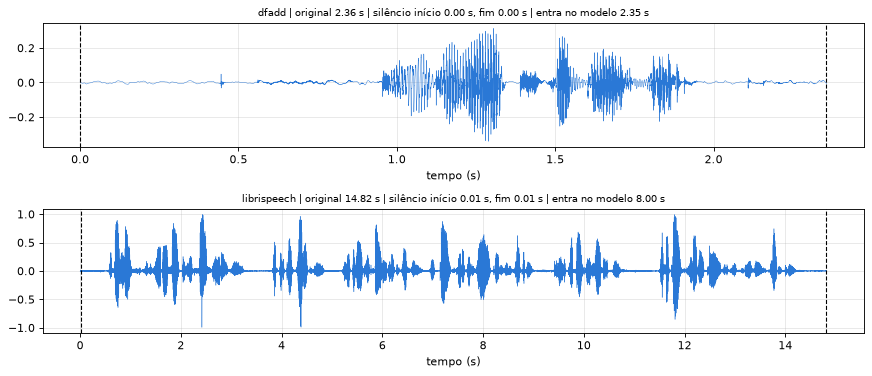

In [5]:
from IPython.display import Audio

from src.preproc import SR, bordas_sem_silencio, ler_mono_16k, preparar_clipe

val_m = df[(df.split == "val") & (df.label == 0)]
exemplos = [val_m[val_m.source_dataset == "dfadd"].sample(1, random_state=SEED).iloc[0],
            val_m[val_m.source_dataset == "librispeech"].sample(1, random_state=SEED).iloc[0]]
fig, axes = plt.subplots(len(exemplos), 1, figsize=(11, 2.4 * len(exemplos)))
for ax, ex in zip(axes, exemplos):
    x, sr = ler_mono_16k(ex.path)
    ini, fim = bordas_sem_silencio(x, TOP_DB)
    clipe, est = preparar_clipe(x, sr, top_db=TOP_DB, min_s=MIN_S, max_s=MAX_S)
    t = np.arange(x.numel()) / SR
    ax.plot(t, x.numpy(), color=REAL_C, lw=0.4)
    ax.axvline(ini / SR, color="black", ls="--", lw=1)
    ax.axvline(fim / SR, color="black", ls="--", lw=1)
    ax.set_title(f"{ex.source_dataset} | original {est['dur_original_s']:.2f} s | silêncio início {est['silencio_inicio_s']:.2f} s, "
                 f"fim {est['silencio_fim_s']:.2f} s | entra no modelo {est['dur_entrada_s']:.2f} s", fontsize=9)
    ax.set_xlabel("tempo (s)")
    display(Markdown(f"**{ex.source_dataset}** (original e depois do corte):"))
    display(Audio(x.numpy(), rate=SR))
    display(Audio(clipe.numpy(), rate=SR))
fig.tight_layout()
plt.show()

**Conclusão:** o corte tira as pausas do começo e do fim (as linhas tracejadas), e o que entra no modelo é a fala sem completar. Áudios longos (como os de audiolivro) ainda são cortados no centro em 8 s.

## 5. Análise exploratória

### 5.1 Acurácia da v3, retroativa (Parte A)
**O que faz:** mostra a acurácia e a acurácia balanceada (média do recall de real e do de fake) das seis execuções da v3, com o limiar da validação (ponto de EER) e com 0,5, ao lado da **acurácia trivial** ("sempre a classe majoritária"). Calculado por `scripts/acuracias_v3.py` só com as notas já salvas (nenhum teste consultado). **Por quê:** a acurácia é a métrica mais intuitiva, mas **engana em banco desbalanceado**: o dev_shift tem 81% de reais, então "chamar tudo de real" já acerta 81%. A balanceada vale 0,5 para qualquer regra que ignore o áudio.

In [6]:
a3 = pd.read_csv("results/v3_acuracias.csv")
cols = ["experimento", "conjunto", "limiar (prob.)", "AUC", "EER", "acurácia", "acurácia balanceada",
        "acurácia (0,5)", "acurácia balanceada (0,5)", "acurácia trivial"]
display(a3[cols].round(3))

,experimento,conjunto,limiar (prob.),AUC,EER,acurácia,acurácia balanceada,"acurácia (0,5)","acurácia balanceada (0,5)",acurácia trivial
0,v3_repeat_s42,validação,0.641,0.998,0.012,0.988,0.988,0.988,0.987,0.693
1,v3_repeat_s42,dev_shift,0.641,0.241,0.696,0.216,0.434,0.207,0.439,0.813
2,v3_zero_s42,validação,0.919,0.996,0.022,0.978,0.978,0.973,0.960,0.693
3,v3_zero_s42,dev_shift,0.919,0.274,0.665,0.212,0.400,0.196,0.479,0.813
4,v3_repeat_s123,validação,0.787,0.998,0.017,0.983,0.983,0.984,0.980,0.693
5,v3_repeat_s123,dev_shift,0.787,0.378,0.592,0.312,0.503,0.273,0.515,0.813
6,v3_zero_s123,validação,0.128,0.999,0.010,0.990,0.990,0.985,0.988,0.693
7,v3_zero_s123,dev_shift,0.128,0.146,0.794,0.164,0.365,0.155,0.275,0.813
8,v3_repeat_s2026,validação,0.627,0.998,0.012,0.988,0.988,0.989,0.988,0.693
9,v3_repeat_s2026,dev_shift,0.627,0.228,0.705,0.191,0.432,0.186,0.442,0.813


**Conclusão:** na validação, a acurácia da v3 fica perto de 0,99. No dev_shift, a acurácia (0,16 a 0,34) fica **muito abaixo da trivial (0,81)** e a balanceada (0,37 a 0,50) não passa do acaso: o modelo erra a maior parte dos reais de internet. É o mesmo diagnóstico da AUC abaixo de 0,5, agora numa escala mais fácil de explicar.

### 5.2 Estatísticas baratas por fonte e classe
**O que faz:** resume, a partir do cache, a duração original, o silêncio inicial e final, o RMS e a largura de banda de cada fonte e classe, no treino, na validação e no dev_shift. **Por quê:** se essas estatísticas forem muito diferentes entre real e fake **dentro do treino**, o modelo pode aprender um atalho (por exemplo, "silêncio longo no fim = real"). É a base da Parte F (seção 7.4).

In [7]:
from src.preproc import COLS_ATALHO

metas = []
for conj in ("treino", "val", "dev_shift"):
    c = Conjunto(CACHE_DIR, conj)
    if len(c):
        metas.append(c.meta.assign(conjunto=conj))
if metas:
    M = pd.concat(metas, ignore_index=True).assign(classe=lambda x: x.label.map({0: "real", 1: "fake"}))
    resumo_est = (M.groupby(["conjunto", "source_dataset", "classe"], sort=False)[COLS_ATALHO + ["corte_desfeito"]]
                    .median().round(2))
    resumo_est["n"] = M.groupby(["conjunto", "source_dataset", "classe"], sort=False).size()
    display(resumo_est)
    print(f"cortes desfeitos (sobrava < {MIN_S} s): {int(M.corte_desfeito.sum())} de {len(M)} | "
          f"erros de leitura: {int(M.erro_leitura.sum())}")
else:
    pendente("o cache de características")

dur_original_s  silencio_inicio_s  \
conjunto  source_dataset  classe                                      
treino    asvspoof2019_la fake              3.24               0.38   
          dfadd           real              3.12               0.00   
                          fake              3.81               0.19   
          asvspoof2019_la real              3.32               0.95   
          shiftyspeech    real              5.32               0.29   
          codecfake_plus  fake              6.50               0.09   
          shiftyspeech    fake              5.28               0.33   
          codecfake_plus  real              5.68               0.21   
          librispeech     real             13.92               0.20   
val       shiftyspeech    fake              4.83               0.34   
          dfadd           fake              3.84               0.20   
          librispeech     real             13.99               0.21   
          dfadd           real              3.16               0.00   
          shiftyspeech    real              4.83               0.31   
          codecfake_plus  fake              4.63               0.05   
                          real              3.00               0.00   
dev_shift in_the_wild     real              3.05               0.26   
                          fake              3.58               0.24   

                                  silencio_fim_s  rms_db  pico_db  banda_hz  \
conjunto  source_dataset  classe                                              
treino    asvspoof2019_la fake              0.31  -18.34    -0.00   3531.25   
          dfadd           real              0.01  -26.00    -7.15   3750.00   
                          fake              0.04  -23.20    -4.32   3437.50   
          asvspoof2019_la real              0.31  -18.75    -0.00   3750.00   
          shiftyspeech    real              0.28  -24.84    -6.72   3781.25   
          codecfake_plus  fake              0.02  -25.10    -6.51   4718.75   
          shiftyspeech    fake              0.30  -25.06    -6.42   3750.00   
          codecfake_plus  real              0.20  -24.73    -5.75   4812.50   
          librispeech     real              0.16  -24.81    -5.63   4312.50   
val       shiftyspeech    fake              0.31  -25.14    -6.53   4343.75   
          dfadd           fake              0.07  -23.41    -4.46   3218.75   
          librispeech     real              0.19  -24.61    -5.21   4343.75   
          dfadd           real              0.01  -25.32    -6.46   3468.75   
          shiftyspeech    real              0.26  -24.77    -7.06   4343.75   
          codecfake_plus  fake              0.06  -23.34    -5.05   4062.50   
                          real              0.01  -23.48    -5.86   4125.00   
dev_shift in_the_wild     real              0.11  -28.61   -11.08   3343.75   
                          fake              0.19  -25.97    -8.26   2718.75   

                                  corte_desfeito      n  
conjunto  source_dataset  classe                         
treino    asvspoof2019_la fake               0.0   6431  
          dfadd           real               0.0   4864  
                          fake               0.0   6413  
          asvspoof2019_la real               0.0   4864  
          shiftyspeech    real               0.0   4707  
          codecfake_plus  fake               0.0    743  
          shiftyspeech    fake               0.0   6413  
          codecfake_plus  real               0.0    702  
          librispeech     real               0.0   4863  
val       shiftyspeech    fake               0.0   3471  
          dfadd           fake               0.0  10336  
          librispeech     real               0.0   1852  
          dfadd           real               0.0   2831  
          shiftyspeech    real               0.0   1157  
          codecfake_plus  fake               0.0    188  
                          real               0

cortes desfeitos (sobrava < 0.5 s): 33 de 70613 | erros de leitura: 0


**Conclusão:** dentro das fontes do treino há diferenças baratas entre real e fake: no DFADD, os reais quase não têm silêncio nas bordas (mediana de 0,00 s no início, contra 0,19 s nos fakes); no ASVspoof 2019, os reais têm mais silêncio inicial (0,95 s contra 0,38 s). Um modelo pode usar essas pistas sem "ouvir" a voz; o corte de silêncio (seção 4) tira parte delas. No dev_shift, o real é mais baixo (RMS −28,6 dB contra −26,0 dB) e o fake tem banda mais estreita (2,7 kHz contra 3,3 kHz). A seção 7.4 mede se essas estatísticas sozinhas preveem o rótulo.

## 6. Treinamento

### 6.1 Extração: vazão, orçamento e o que foi feito
**O que faz:** lê a vazão medida antes da execução (`results/v4_vazao.json`), o orçamento cumulativo (`results/v4_estado.json`) e o marcador da extração. **Por quê:** os tamanhos do treino foram dimensionados pela vazão medida, e o tempo gasto acumula entre tentativas (não recomeça se o PC reiniciar).

In [8]:
for nome in ("vazao", "estado", "extracao_concluido"):
    p = RESULTS_DIR / f"v4_{nome}{SUFIXO}.json"
    if existe(p):
        j = json.loads(p.read_text(encoding="utf-8"))
        j.pop("codigo", None)
        print(f"--- {p}\n" + json.dumps(j, ensure_ascii=False, indent=1)[:2500])
    else:
        pendente(str(p))

--- results\v4_vazao.json
{
 "n": 500,
 "num_workers": 4,
 "segundos_total": 11.3,
 "segundos_ate_1o_lote": 1.8,
 "clipes_por_s": 44.12,
 "clipes_por_s_sem_partida": 52.5,
 "segundos_gpu": 9.0,
 "clipes_por_s_so_gpu": 55.56,
 "carga_modelo_s": 7.4,
 "pico_gpu_gb": 3.76,
 "clipes_com_nan": 0,
 "duracao_media_manifest_s": 5.67,
 "medido_em": "2026-11-09T22:32:56",
 "pico_memoria_gb_processo_e_workers": 11.45,
 "pico_memoria_gb_sistema": 34.69,
 "memoria_por_processo_no_meio": [
  {
   "papel": "principal",
   "pid": 37140,
   "commit_gb": 7.5
  },
  {
   "papel": "worker",
   "pid": 2504,
   "commit_gb": 0.91
  },
  {
   "papel": "worker",
   "pid": 32664,
   "commit_gb": 0.91
  },
  {
   "papel": "worker",
   "pid": 19996,
   "commit_gb": 0.96
  },
  {
   "papel": "worker",
   "pid": 29132,
   "commit_gb": 0.9
  }
 ],
 "fontes": {
  "asvspoof2019_la": 113,
  "codecfake_plus": 113,
  "shiftyspeech": 112,
  "dfadd": 112,
  "librispeech": 50
 },
 "lotes_gpu": 13,
 "linhas_vazias": 106,
 "r

### 6.2 Regressão logística por camada
**O que faz:** para cada uma das 25 saídas do modelo, uma regressão logística sobre a **média no tempo** (1.024 números por áudio), padronizada com a média e o desvio do treino; o C de cada camada é escolhido pela EER média por fonte da validação. Mostra a EER da validação (que **escolhe**) e a AUC do dev_shift (só **reportada**) por camada, com a faixa da v3. **Por quê:** cada camada do modelo guarda um tipo de informação (as primeiras, mais acústica; as do meio, mais fonética; as últimas, mais próxima do objetivo do pré-treino). Isto mostra **onde** está a pista de real/fake. ⚠️ Fora da trilha: regressão logística por camada ("probing") com o scikit-learn.

,camada,C,val EER média por fonte,val EER global,dev AUC,dev EER,dev acurácia balanceada,dev recall fake,dev falso alarme real,iterações,segundos
0,0,1.00,0.222,0.077,0.538,0.483,0.551,0.896,0.795,699,17.6
1,1,0.10,0.191,0.056,0.566,0.452,0.563,0.952,0.825,198,9.1
2,2,1.00,0.164,0.048,0.624,0.397,0.545,0.964,0.874,189,6.1
3,3,1.00,0.107,0.030,0.793,0.272,0.680,0.975,0.616,122,4.4
4,4,1.00,0.087,0.025,0.897,0.177,0.789,0.966,0.387,75,3.3
5,5,0.10,0.061,0.012,0.972,0.075,0.873,0.975,0.228,51,3.8
6,6,0.01,0.062,0.011,0.991,0.035,0.913,0.987,0.161,52,3.5
7,7,0.01,0.060,0.012,0.991,0.035,0.935,0.981,0.111,45,3.0
8,8,0.01,0.064,0.012,0.990,0.038,0.926,0.983,0.131,52,3.4
9,9,0.01,0.066,0.015,0.989,0.038,0.912,0.984,0.159,55,3.7


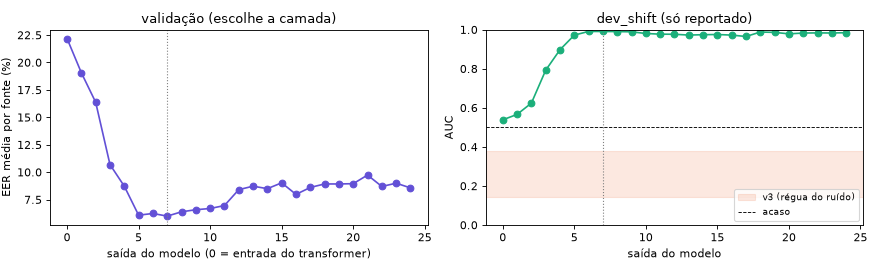

In [9]:
arq_cam = arq_result("camadas", "csv")
if existe(arq_cam):
    cam = pd.read_csv(arq_cam)
    display(cam[["camada", "C", "val EER média por fonte", "val EER global", "dev AUC", "dev EER",
                 "dev acurácia balanceada", "dev recall fake", "dev falso alarme real", "iterações", "segundos"]].round(3))
    png = arq_result("camadas", "png")
    if existe(png):
        from IPython.display import Image
        display(Image(filename=str(png)))
else:
    pendente("results/v4_camadas.csv")

**Conclusão:** as camadas do meio são as melhores na validação (5 a 9: EER média por fonte de 6,0% a 6,6%; a melhor é a 7, com 6,0%); a entrada do transformer (0) e as primeiras camadas são as piores (22% na 0), e a última (24) fica em 8,6%. No dev_shift, todas a partir da 5 passam de 0,97 de AUC, muito acima da régua da v3 (0,146 a 0,378). Quem escolheu a camada foi a validação; o dev_shift só foi reportado.

### 6.3 Soma ponderada das camadas (linear e MLP), 3 seeds
**O que faz:** mostra as curvas de treino (EER média por fonte da validação por época) e os **pesos aprendidos** de cada camada (softmax) das cabeças de soma ponderada. **Por quê:** os pesos dizem quais camadas a cabeça preferiu, sem escolher uma só; as 3 seeds mostram o acaso dessas cabeças. ⚠️ Fora da trilha: soma ponderada aprendida de camadas (padrão do benchmark SUPERB) e o otimizador AdamW.

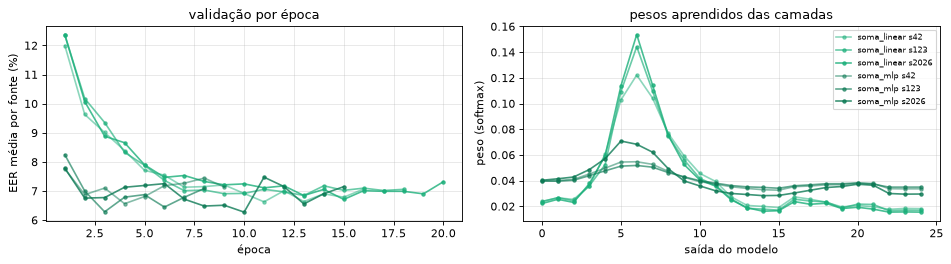

In [10]:
hists = {}
for nome in ("soma_linear", "soma_mlp"):
    for s in SEEDS_CABECA:
        p = arq_result(f"{nome}_s{s}_historico", "csv")
        if existe(p):
            hists[(nome, s)] = pd.read_csv(p)
if hists:
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
    for (nome, s), h in hists.items():
        ax[0].plot(h["época"], 100 * h["EER média por fonte (val)"], marker="o", ms=3, color=COR_CAB[nome],
                   alpha=0.5 + 0.15 * SEEDS_CABECA.index(s), label=f"{nome} s{s}")
        j = json.loads(arq_result(f"{nome}_s{s}", "json").read_text(encoding="utf-8"))
        ax[1].plot(range(25), j["pesos_camadas"], marker=".", color=COR_CAB[nome],
                   alpha=0.5 + 0.15 * SEEDS_CABECA.index(s), label=f"{nome} s{s}")
    ax[0].set(xlabel="época", ylabel="EER média por fonte (%)", title="validação por época")
    ax[1].set(xlabel="saída do modelo", ylabel="peso (softmax)", title="pesos aprendidos das camadas")
    ax[1].legend(fontsize=7)
    fig.tight_layout()
    plt.show()
else:
    pendente("os históricos das somas ponderadas")

**Conclusão:** as somas ponderadas também dão os maiores pesos às camadas 5, 6 e 7, as mesmas que a regressão por camada achou. Nas 3 seeds, a AUC do dev_shift ficou entre 0,982 e 0,986 (linear e MLP): o acaso entre seeds aqui é de ~0,005, bem menor que o da CNN da v3 (0,15 a 0,23).

## 7. Avaliação

### 7.1 Métricas e limiar
- **AUC e EER** continuam sendo as métricas principais: não dependem de limiar nem da proporção real/fake.
- **Acurácia e acurácia balanceada** (Parte A) com o limiar fixado na validação (ponto de EER da validação inteira) e com 0,5, sempre ao lado da acurácia trivial.
- **Recall de fake** e **falso alarme de real** usam o limiar da validação.
- Cada clipe é avaliado uma vez (até 8 s, recorte central depois do corte de silêncio), e não por janelas como na v3.

### 7.2 Todas as cabeças, lado a lado com a v3
**O que faz:** junta numa tabela a melhor camada, as concatenações, as somas ponderadas (por seed e o ensemble das 3) e o classificador de atalho, e coloca ao lado as seis execuções da CNN da v3 (a régua do ruído). Diz qual cabeça a validação escolheu e o veredito pelo critério pré-registrado. **Por quê:** é a comparação principal da versão (AUC, EER e acurácia balanceada do dev_shift).

In [11]:
arq_cab = arq_result("cabecas", "csv")
if existe(arq_cab):
    cab = pd.read_csv(arq_cab)
    cols = ["cabeça", "seed", "val EER média por fonte", "val EER global", "dev AUC", "dev EER", "dev acurácia",
            "dev acurácia balanceada", "dev acurácia trivial", "dev recall fake", "dev falso alarme real"]
    v3 = pd.read_csv("results/v3_acuracias.csv")
    v3d = v3[v3.conjunto == "dev_shift"].set_index("experimento")
    v3v = v3[v3.conjunto == "validação"].set_index("experimento")
    v3t = pd.DataFrame({"cabeça": "CNN v3 " + v3d.index, "seed": v3d.seed.values, "val EER média por fonte": np.nan,
                        "val EER global": v3v.EER.values, "dev AUC": v3d.AUC.values, "dev EER": v3d.EER.values,
                        "dev acurácia": v3d["acurácia"].values, "dev acurácia balanceada": v3d["acurácia balanceada"].values,
                        "dev acurácia trivial": v3d["acurácia trivial"].values, "dev recall fake": v3d["recall fake"].values,
                        "dev falso alarme real": v3d["falso alarme"].values})
    display(pd.concat([cab[cols], v3t], ignore_index=True).round(3))
    rs = json.loads(arq_result("resumo", "json").read_text(encoding="utf-8"))
    print("candidatas (EER média por fonte na validação):")
    print(pd.DataFrame(rs["candidatas"]).round(4).to_string(index=False))
    print(f"\ncabeça final (escolhida pela validação): {rs['cabeça_final_pela_validação']}")
    print(f"AUC do dev_shift por seed: {rs['dev_AUC_por_seed_cabeça_final']}")
    print(f"veredito (pré-registro c): {rs['veredito_pré_registro_c']}")
    print(f"regra das 3 seeds nas somas: {rs['regra_3_seeds_somas']}")
else:
    pendente("results/v4_cabecas.csv")

,cabeça,seed,val EER média por fonte,val EER global,dev AUC,dev EER,dev acurácia,dev acurácia balanceada,dev acurácia trivial,dev recall fake,dev falso alarme real
0,rl_camada_7,-,0.060,0.012,0.991,0.035,0.906,0.935,0.813,0.981,0.111
1,concat_top3,-,0.059,0.010,0.983,0.059,0.843,0.897,0.813,0.981,0.188
2,concat_top4,-,0.060,0.010,0.990,0.040,0.876,0.917,0.813,0.982,0.148
3,soma_linear,42,0.066,0.013,0.983,0.048,0.870,0.911,0.813,0.976,0.154
4,soma_linear,123,0.068,0.013,0.982,0.049,0.864,0.907,0.813,0.976,0.161
5,soma_linear,2026,0.067,0.013,0.982,0.049,0.852,0.900,0.813,0.976,0.176
6,soma_linear_ensemble,média das 3,0.070,0.013,0.982,0.049,0.862,0.906,0.813,0.976,0.164
7,soma_mlp,42,0.066,0.013,0.982,0.063,0.804,0.872,0.813,0.980,0.236
8,soma_mlp,123,0.063,0.012,0.986,0.052,0.814,0.879,0.813,0.982,0.224
9,soma_mlp,2026,0.063,0.010,0.983,0.054,0.875,0.911,0.813,0.969,0.147


candidatas (EER média por fonte na validação):
     cabeça  val EER média por fonte
concat_top3                   0.0592
concat_top4                   0.0598
rl_camada_7                   0.0599
   soma_mlp                   0.0638
soma_linear                   0.0673

cabeça final (escolhida pela validação): concat_top3
AUC do dev_shift por seed: [0.983269123392956]
veredito (pré-registro c): melhora clara (AUC do dev_shift > 0,6)
regra das 3 seeds nas somas: {'soma_linear': {'aucs': [0.9828, 0.9822, 0.9816], 'todas_acima_0_5': True}, 'soma_mlp': {'aucs': [0.9821, 0.9863, 0.983], 'todas_acima_0_5': True}}


**Conclusão:** pela validação, a cabeça final é a `concat_top3` (camadas 5, 6 e 7; EER média por fonte 5,92%), mas a diferença para as outras candidatas é pequena (5,92% a 6,73%). No dev_shift: AUC 0,983, EER 5,9% e acurácia balanceada 0,897 (limiar da validação), contra AUC de 0,146 a 0,378 e acurácia balanceada de 0,365 a 0,503 nas seis CNNs da v3. Pelo critério pré-registrado (c), é **melhora clara** (AUC > 0,6). Atenção à acurácia: no dev_shift ela é 0,843, só um pouco acima da trivial (0,813), porque o limiar da validação acusa 18,8% dos reais; a acurácia balanceada mostra melhor o ganho.

### 7.3 dev_shift por duração original
**O que faz:** AUC e EER do dev_shift por faixa de duração original (< 2 s, 2 a < 4 s, ≥ 4 s), para todas as cabeças. **Por quê:** nas versões anteriores a inversão era pior nos áudios curtos; com entrada sem padding, dá para ver se isso continua.

In [12]:
if existe(arq_cab):
    fx = ["cabeça", "seed"] + [f"dev {m} {f}" for f in FAIXAS_DURACAO for m in ("n", "AUC", "EER")]
    display(cab[[c for c in fx if c in cab.columns]].round(3))
else:
    pendente("results/v4_cabecas.csv")

,cabeça,seed,dev n < 2 s,dev AUC < 2 s,dev EER < 2 s,dev n 2 a < 4 s,dev AUC 2 a < 4 s,dev EER 2 a < 4 s,dev n ≥ 4 s,dev AUC ≥ 4 s,dev EER ≥ 4 s
0,rl_camada_7,-,2420,0.954,0.097,4531,0.994,0.029,3663,0.998,0.012
1,concat_top3,-,2420,0.932,0.131,4531,0.987,0.062,3663,0.997,0.021
2,concat_top4,-,2420,0.949,0.106,4531,0.993,0.038,3663,0.999,0.011
3,soma_linear,42,2420,0.932,0.116,4531,0.986,0.044,3663,0.996,0.013
4,soma_linear,123,2420,0.931,0.122,4531,0.985,0.043,3663,0.996,0.016
5,soma_linear,2026,2420,0.930,0.124,4531,0.985,0.044,3663,0.996,0.016
6,soma_linear_ensemble,média das 3,2420,0.931,0.119,4531,0.985,0.043,3663,0.996,0.014
7,soma_mlp,42,2420,0.927,0.138,4531,0.982,0.066,3663,0.996,0.020
8,soma_mlp,123,2420,0.948,0.109,4531,0.986,0.058,3663,0.997,0.020
9,soma_mlp,2026,2420,0.941,0.113,4531,0.983,0.053,3663,0.995,0.021


### 7.4 Diagnóstico de atalhos (Parte F)
**O que faz:** (a) regressão logística que prevê o rótulo **só** com duração, silêncio inicial e final, RMS, pico e largura de banda, treinada no treino e avaliada na validação e no dev_shift (e cada estatística sozinha); (b) um classificador que prevê a **fonte** usando só áudios reais (pelas estatísticas e pela melhor camada do modelo); (c) a probabilidade média de fake dos reais e dos fakes de cada fonte; (d) um controle de sanidade: a mesma regressão da melhor camada com os rótulos do treino embaralhados (tem que dar AUC perto de 0,5). **Por quê:** se (a) passar bem do acaso, o rótulo vaza por propriedades da gravação, e o detector pode estar aprendendo "de que banco veio" em vez de "é sintético". Não custa nada: as estatísticas foram calculadas na extração.

In [13]:
arq_at = arq_result("atalhos", "json")
if existe(arq_at):
    at = json.loads(arq_at.read_text(encoding="utf-8"))
    a_ = at["a_rotulo_por_estatisticas"]
    print(f"(a) rótulo só pelas estatísticas: val AUC {a_['val AUC']:.3f} | val EER média/fonte {100 * a_['val EER média por fonte']:.1f}% | "
          f"dev AUC {a_['dev AUC']:.3f} | dev acc. balanceada {a_['dev acurácia balanceada']:.3f}")
    print("    coeficientes (estatísticas padronizadas; positivo = empurra para fake):", a_["coeficientes"])
    display(pd.DataFrame(at["a_por_estatistica"]).round(3))
    for k in ("b_fonte_por_estatisticas", "b_fonte_por_camada"):
        b_ = at[k]
        print(f"(b) {k}: acurácia {b_['acurácia']:.3f} | balanceada {b_['acurácia balanceada']:.3f} | "
              f"acaso {b_['acaso (1/nº de fontes da validação)']:.3f} | trivial {b_['acurácia trivial (fonte majoritária)']:.3f}")
    display(pd.DataFrame(at["b_confusao_estatisticas"]).fillna(0).astype(int))
    print(f"(c) probabilidade de fake por fonte (regressão logística na camada {at['c_nota_por_fonte']['camada']}):")
    display(pd.DataFrame(at["c_nota_por_fonte"]["linhas"]).round(3))
    d_ = at["d_controle_rotulos_embaralhados"]
    print(f"(d) controle de sanidade, rótulos do treino embaralhados (camada {d_['camada']}): val AUC {d_['val AUC']:.3f} | "
          f"dev AUC {d_['dev AUC']:.3f} (tem que ficar perto de 0,5)")
else:
    pendente("results/v4_atalhos.json")

(a) rótulo só pelas estatísticas: val AUC 0.668 | val EER média/fonte 49.5% | dev AUC 0.523 | dev acc. balanceada 0.521
    coeficientes (estatísticas padronizadas; positivo = empurra para fake): {'dur_original_s': -0.4328, 'silencio_inicio_s': -0.3905, 'silencio_fim_s': 0.3098, 'rms_db': 0.2467, 'pico_db': 0.1019, 'banda_hz': -0.0885}


,estatística,val AUC,val EER média por fonte,dev AUC,dev acurácia balanceada
0,dur_original_s,0.568,0.596,0.413,0.443
1,silencio_inicio_s,0.387,0.610,0.510,0.392
2,silencio_fim_s,0.568,0.407,0.546,0.611
3,rms_db,0.611,0.460,0.602,0.562
4,pico_db,0.579,0.444,0.648,0.571
5,banda_hz,0.580,0.482,0.596,0.561


(b) b_fonte_por_estatisticas: acurácia 0.780 | balanceada 0.571 | acaso 0.250 | trivial 0.472
(b) b_fonte_por_camada: acurácia 0.919 | balanceada 0.799 | acaso 0.250 | trivial 0.472


,asvspoof2019_la,dfadd,librispeech,shiftyspeech
codecfake_plus,4,130,1,29
dfadd,39,2471,36,285
librispeech,0,68,1554,230
shiftyspeech,72,270,154,661


(c) probabilidade de fake por fonte (regressão logística na camada 7):


,conjunto,fonte,classe,n,prob. média de fake,prob. mediana de fake,% acima do limiar
0,validação,codecfake_plus,real,164,0.144,0.001,0.140
1,validação,codecfake_plus,fake,188,0.759,0.974,0.745
2,validação,dfadd,real,2831,0.005,0.001,0.000
3,validação,dfadd,fake,10336,0.986,0.999,0.996
4,validação,librispeech,real,1852,0.006,0.000,0.003
5,validação,shiftyspeech,real,1157,0.066,0.004,0.040
6,validação,shiftyspeech,fake,3471,0.956,0.998,0.975
7,dev_shift,in_the_wild,real,8633,0.135,0.003,0.111
8,dev_shift,in_the_wild,fake,1981,0.979,1.000,0.981


(d) controle de sanidade, rótulos do treino embaralhados (camada 7): val AUC 0.474 | dev AUC 0.486 (tem que ficar perto de 0,5)


**Conclusão:** (a) só com duração, silêncio, volume e banda, a regressão chega a AUC 0,668 na validação, acima do 0,6 do pré-registro (f): **há indício de atalho nos dados** (por exemplo, no DFADD os reais quase não têm silêncio nas bordas). Mas no dev_shift ela fica em 0,523, o acaso: esse atalho não explica o desempenho do modelo fora do domínio. (b) A camada 7 reconhece de que banco vem um áudio real bem melhor que as estatísticas (acurácia balanceada 0,80 contra 0,57; acaso 0,25): o modelo carrega a "marca" do banco de origem, o que é um risco. (d) Com os rótulos embaralhados, a AUC fica perto de 0,5 (0,474 e 0,486): nenhum sinal de vazamento no código.

### 7.5 Ablação do corte de silêncio
**O que faz:** compara, na melhor camada e com o mesmo C, a regressão logística treinada e avaliada **com** e **sem** corte de silêncio, nos **mesmos áudios** (10 mil de treino, 5 mil de validação e o dev_shift inteiro). Só existe se o orçamento de extração permitiu re-extrair esse subconjunto. **Por quê:** separa o efeito do corte do efeito do modelo novo.

In [14]:
arq_ab = arq_result("ablacao_corte", "json")
if existe(arq_ab):
    ab = json.loads(arq_ab.read_text(encoding="utf-8"))
    ks = ["val EER média por fonte", "val EER global", "dev AUC", "dev EER", "dev acurácia balanceada", "n_treino"]
    display(pd.DataFrame({r: {k: ab[r][k] for k in ks} for r in ("com corte", "sem corte")}).T.round(3))
    print("silêncio mediano no dev_shift (s):", ab["exemplos_silencio"])
else:
    pendente("a ablação do corte (results/v4_ablacao_corte.json; depende do orçamento)")

,val EER média por fonte,val EER global,dev AUC,dev EER,dev acurácia balanceada,n_treino
com corte,0.076,0.017,0.992,0.028,0.956,10000.0
sem corte,0.079,0.016,0.990,0.029,0.949,10000.0


silêncio mediano no dev_shift (s): {'silencio_inicio_mediana_s': 0.25, 'silencio_fim_mediana_s': 0.146}


**Conclusão:** com e sem corte de silêncio, nos mesmos áudios, os números são praticamente iguais (EER média por fonte 7,6% × 7,9%; AUC do dev_shift 0,992 × 0,990): o ganho da v4 **não vem do corte de silêncio**.

### 7.6 Teste final (avaliado uma única vez, numa etapa separada)
**O que faz:** lê do disco o que `scripts/v4_teste.py` gravou (pelo vigia `scripts/vigia_v4_teste.ps1`): a amostra de cada banco, a escolha do S0, as conferências do reajuste do S1 e do S2, os coeficientes do S3 e os limiares. **Nada é recalculado aqui.** **Por quê:** o teste final é avaliado **uma vez**, com tudo decidido antes (pré-registro em `docs/HISTORICO_VERSOES.md`, "v4 - teste final: pré-registro", 2026-11-10 07:25).

Os quatro sistemas, todos nos **mesmos** clipes:
- **S0:** a CNN da v3 com menor EER média por fonte na validação (`v3_zero_s123`), janelas de 4 s com passo de 2 s;
- **S1 ("só transfer learning"):** XLS-R congelado, **só a última camada (24)**, média no tempo, regressão logística;
- **S2 (v4 final):** a cabeça `concat_top3` (camadas 5, 6 e 7), escolhida pela validação na v4;
- **S3 (v4 + CNN):** regressão logística de duas entradas (logits do S2 e do S0), treinada **só na validação**.

Dois limiares, cada sistema com os seus: **A** = ponto de EER da validação; **B** = ponto de EER do dev_shift. ⚠️ Fora da trilha: o bootstrap (intervalos de 95% reamostrando os clipes do teste dentro de cada classe); ele mede **só a incerteza da amostra de teste**, não a variação do treino.

In [15]:
arq_tf = RESULTS_DIR / f"v4_teste_final{SUFIXO}.csv"
arq_tr = RESULTS_DIR / f"v4_teste_final_resumo{SUFIXO}.json"
if existe(arq_tf) and existe(RESULTS_DIR / f"v4_teste_final_concluido{SUFIXO}.json"):
    tf = pd.read_csv(arq_tf)
    tr_ = json.loads(arq_tr.read_text(encoding="utf-8"))
    teste = tf[tf.conjunto == "teste"]
    tam = (teste[(teste.sistema == "S0") & (teste.limiar == "A") & (teste["métrica"] == "AUC")]
           [["banco", "tipo", "n real", "n fake", "excluídos (erro de leitura)"]].reset_index(drop=True))
    display(Markdown("**Amostra de cada banco** (até 5.000 por classe, seed 42):"))
    display(tam)
    esc = json.loads((RESULTS_DIR / f"v4_teste_escolha_s0{SUFIXO}.json").read_text(encoding="utf-8"))
    display(Markdown(f"**S0 escolhido pela validação:** `{tr_['s0']}`"))
    display(pd.DataFrame(esc).round(4))
    ch = tr_["checagem"]
    print(f"S1: C = {ch['S1']['C']:g} (na v4: {ch['S1']['C_na_v4']:g}); diferença máxima das notas para a v4: "
          f"val {ch['S1']['dif_max_val_vs_v4']:.1e}, dev_shift {ch['S1']['dif_max_dev_vs_v4']:.1e}")
    print(f"S2: camadas {ch['S2']['camadas']}, C = {ch['S2']['C']:g}; diferença máxima das notas para as gravadas na v4: "
          f"val {ch['S2']['dif_max_val_vs_v4']:.1e}, dev_shift {ch['S2']['dif_max_dev_vs_v4']:.1e}")
    s3 = ch["S3"]
    print(f"S3 (entradas padronizadas pela validação): intercepto {s3['intercepto']:.3f} | "
          f"peso do S2 {s3['coef_S2_padronizado']:.3f} | peso do S0 {s3['coef_S0_padronizado']:.3f}")
    print("limiares (logit):", {s: {k: round(v, 3) for k, v in d.items()} for s, d in tr_["limiares_logit"].items()})
else:
    teste = None
    pendente("o teste final (results/v4_teste_final.csv e o marcador results/v4_teste_final_concluido.json)")

**Amostra de cada banco** (até 5.000 por classe, seed 42):

,banco,tipo,n real,n fake,excluídos (erro de leitura)
0,in_the_wild,principal,5000,5000,0
1,llamapartialspoof,principal,5000,5000,0
2,brspeech_df,principal,1320,5000,0
3,coraa,só real,5000,0,0
4,asvspoof2019_la,secundário,5000,5000,0
5,asvspoof2021_df,secundário,5000,5000,0


**S0 escolhido pela validação:** `v3_zero_s123`

,experimento,val EER média por fonte,dev_shift AUC (janelas),condição,seed,checkpoint
0,v3_zero_s123,0.1125,0.1455,zero,123,models\v3_zero_s123_cnn.pt
1,v3_zero_s2026,0.1227,0.3773,zero,2026,models\v3_zero_s2026_cnn.pt
2,v3_repeat_s2026,0.1265,0.2284,repeat,2026,models\v3_repeat_s2026_cnn.pt
3,v3_repeat_s123,0.1324,0.3775,repeat,123,models\v3_repeat_s123_cnn.pt
4,v3_zero_s42,0.1373,0.2740,zero,42,models\v3_zero_s42_cnn.pt
5,v3_repeat_s42,0.1414,0.2413,repeat,42,models\v3_repeat_s42_cnn.pt


S1: C = 1 (na v4: 1); diferença máxima das notas para a v4: val 0.0e+00, dev_shift 0.0e+00
S2: camadas [5, 6, 7], C = 0.1; diferença máxima das notas para as gravadas na v4: val 0.0e+00, dev_shift 0.0e+00
S3 (entradas padronizadas pela validação): intercepto 4.746 | peso do S2 5.361 | peso do S0 4.193
limiares (logit): {'S0': {'A': -2.15, 'B': 2.843}, 'S1': {'A': -0.011, 'B': 6.3}, 'S2': {'A': -0.04, 'B': 8.218}, 'S3': {'A': 0.738, 'B': 5.397}}


### 7.7 Teste final: resultados por banco e sistema
**O que faz:** mostra, para cada banco e sistema, nos dois limiares, a **acurácia** (porcentagem de acerto), a acurácia balanceada (com o intervalo bootstrap), a acurácia trivial (sempre a classe majoritária), AUC, EER, recall de fake e falso alarme de real; depois o gráfico e o resumo (média dos três bancos principais e o falso alarme do CORAA). **Por quê:** acurácia sozinha engana em banco desbalanceado (no BRSpeech-DF, 79% dos clipes da amostra são fake); por isso a balanceada e a trivial vão ao lado, e AUC e EER continuam as principais.

**Limiar A (ponto de EER da validação)**; entre colchetes, o intervalo bootstrap de 95% (só a amostra de teste):

métrica                   acurácia   acurácia balanceada acurácia trivial  \
banco             sistema                                                   
in_the_wild       S0         0.336  0.336 [0.329, 0.343]            0.500   
                  S1         0.829  0.829 [0.823, 0.836]            0.500   
                  S2         0.836  0.835 [0.829, 0.842]            0.500   
                  S3         0.641  0.641 [0.634, 0.647]            0.500   
llamapartialspoof S0         0.545  0.545 [0.536, 0.554]            0.500   
                  S1         0.851  0.851 [0.844, 0.858]            0.500   
                  S2         0.855  0.855 [0.849, 0.862]            0.500   
                  S3         0.826  0.826 [0.819, 0.834]            0.500   
brspeech_df       S0         0.671  0.704 [0.691, 0.717]            0.791   
                  S1         0.849  0.671 [0.658, 0.683]            0.791   
                  S2         0.863  0.679 [0.667, 0.693]            0.791   
                  S3         0.867  0.718 [0.705, 0.732]            0.791   
coraa             S0         0.347                     —            1.000   
                  S1         0.644                     —            1.000   
                  S2         0.833                     —            1.000   
                  S3         0.682                     —            1.000   
asvspoof2019_la   S0         0.900  0.901 [0.895, 0.906]            0.500   
                  S1         0.974  0.974 [0.971, 0.977]            0.500   
                  S2         0.981  0.981 [0.979, 0.984]            0.500   
                  S3         0.988  0.988 [0.985, 0.990]            0.500   
asvspoof2021_df   S0         0.665  0.665 [0.656, 0.674]            0.500   
                  S1         0.957  0.956 [0.953, 0.960]            0.500   
                  S2         0.942  0.942 [0.938, 0.947]            0.500   
                  S3         0.829  0.829 [0.822, 0.836]            0.500   

métrica                                     AUC    EER recall fake  \
banco             sistema                                            
in_the_wild       S0       0.114 [0.107, 0.120]  0.822       0.633   
                  S1       0.986 [0.985, 0.988]  0.054       0.992   
                  S2       0.979 [0.976, 0.981]  0.068       0.989   
                  S3       0.888 [0.881, 0.894]  0.189       0.995   
llamapartialspoof S0       0.556 [0.545, 0.568]  0.463       0.762   
                  S1       0.936 [0.931, 0.940]  0.140       0.734   
                  S2       0.925 [0.920, 0.930]  0.147       0.750   
                  S3       0.900 [0.894, 0.906]  0.178       0.800   
brspeech_df       S0       0.735 [0.719, 0.751]  0.293       0.647   
                  S1       0.775 [0.759, 0.791]  0.307       0.976   
                  S2       0.842 [0.827, 0.854]  0.249       0.995   
                  S3       0.840 [0.827, 0.853]  0.253       0.974   
coraa             S0                          —      —           —   
                  S1                          —      —           —   
                  S2                          —      —           —   
                  S3                          —      —           —   
asvspoof2019_la   S0       0.967 [0.963, 0.970]  0.081       0.803   
                  S1       0.997 [0.996, 0.998]  0.023       0.954   
                  S2       0.999 [0.999, 0.999]  0.014       0.964   
                  S3       1.000 [1.000, 1.000]  0.003       0.975   
asvspoof2021_df   S0       0.688 [0.679, 0.699]  0.360       0.721   
                  S1       0.996 [0.995, 0.997]  0.028       0.988   
                  S2       0.997 [0.996, 0.997]  0.026       0.993   
                  S3       0.909 [0.903, 0.915]  0.179       0.984   

métrica                       falso alarme real  
banco             sistema                        
in_the_wild       S0                      0.960  
                  S1      

**Limiar B (ponto de EER do dev_shift)**; entre colchetes, o intervalo bootstrap de 95% (só a amostra de teste):

métrica                   acurácia   acurácia balanceada acurácia trivial  \
banco             sistema                                                   
in_the_wild       S0         0.181  0.181 [0.174, 0.188]            0.500   
                  S1         0.946  0.946 [0.941, 0.950]            0.500   
                  S2         0.931  0.931 [0.925, 0.936]            0.500   
                  S3         0.810  0.810 [0.802, 0.817]            0.500   
llamapartialspoof S0         0.523  0.523 [0.513, 0.533]            0.500   
                  S1         0.734  0.734 [0.726, 0.740]            0.500   
                  S2         0.739  0.738 [0.732, 0.746]            0.500   
                  S3         0.726  0.726 [0.719, 0.733]            0.500   
brspeech_df       S0         0.447  0.609 [0.598, 0.620]            0.791   
                  S1         0.762  0.716 [0.701, 0.729]            0.791   
                  S2         0.839  0.771 [0.757, 0.785]            0.791   
                  S3         0.766  0.754 [0.741, 0.767]            0.791   
coraa             S0         0.587                     —            1.000   
                  S1         0.884                     —            1.000   
                  S2         0.975                     —            1.000   
                  S3         0.913                     —            1.000   
asvspoof2019_la   S0         0.795  0.795 [0.788, 0.802]            0.500   
                  S1         0.902  0.902 [0.896, 0.908]            0.500   
                  S2         0.901  0.901 [0.896, 0.906]            0.500   
                  S3         0.889  0.889 [0.883, 0.895]            0.500   
asvspoof2021_df   S0         0.608  0.608 [0.599, 0.617]            0.500   
                  S1         0.964  0.964 [0.960, 0.967]            0.500   
                  S2         0.964  0.964 [0.961, 0.968]            0.500   
                  S3         0.831  0.831 [0.823, 0.838]            0.500   

métrica                                     AUC    EER recall fake  \
banco             sistema                                            
in_the_wild       S0       0.114 [0.107, 0.120]  0.822       0.210   
                  S1       0.986 [0.985, 0.988]  0.054       0.946   
                  S2       0.979 [0.976, 0.981]  0.068       0.920   
                  S3       0.888 [0.881, 0.894]  0.189       0.806   
llamapartialspoof S0       0.556 [0.545, 0.568]  0.463       0.397   
                  S1       0.936 [0.931, 0.940]  0.140       0.468   
                  S2       0.925 [0.920, 0.930]  0.147       0.479   
                  S3       0.900 [0.894, 0.906]  0.178       0.457   
brspeech_df       S0       0.735 [0.719, 0.751]  0.293       0.331   
                  S1       0.775 [0.759, 0.791]  0.307       0.795   
                  S2       0.842 [0.827, 0.854]  0.249       0.888   
                  S3       0.840 [0.827, 0.853]  0.253       0.775   
coraa             S0                          —      —           —   
                  S1                          —      —           —   
                  S2                          —      —           —   
                  S3                          —      —           —   
asvspoof2019_la   S0       0.967 [0.963, 0.970]  0.081       0.591   
                  S1       0.997 [0.996, 0.998]  0.023       0.804   
                  S2       0.999 [0.999, 0.999]  0.014       0.802   
                  S3       1.000 [1.000, 1.000]  0.003       0.777   
asvspoof2021_df   S0       0.688 [0.679, 0.699]  0.360       0.553   
                  S1       0.996 [0.995, 0.997]  0.028       0.932   
                  S2       0.997 [0.996, 0.997]  0.026       0.935   
                  S3       0.909 [0.903, 0.915]  0.179       0.870   

métrica                       falso alarme real  
banco             sistema                        
in_the_wild       S0                      0.848  
                  S1      

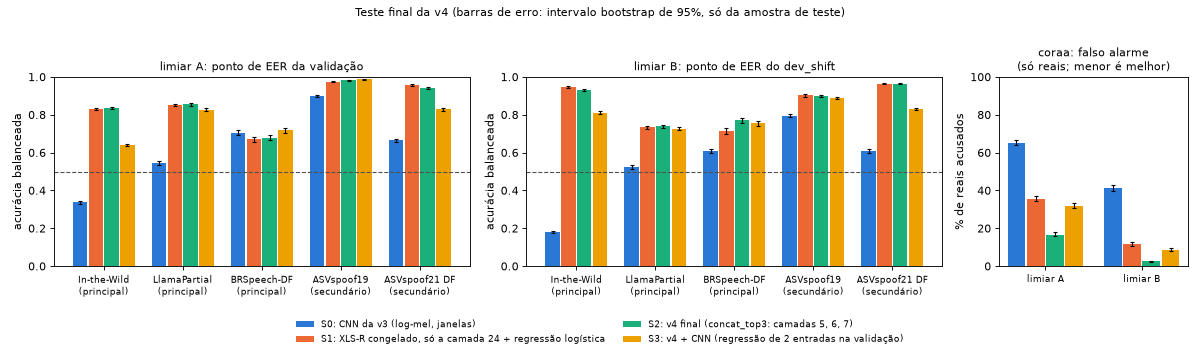

**Resumo** (média simples dos três bancos principais com duas classes; CORAA à parte):

,sistema,limiar,média acurácia (3 principais),média acurácia balanceada (3 principais),média acurácia trivial (3 principais),média AUC (3 principais),coraa falso alarme,coraa falso alarme IC
0,S0,A,0.517,0.529,0.597,0.468,0.653,"[0.638795, 0.666]"
1,S0,B,0.384,0.438,0.597,0.468,0.413,"[0.399, 0.427]"
2,S1,A,0.843,0.784,0.597,0.899,0.356,"[0.342, 0.3688]"
3,S1,B,0.814,0.798,0.597,0.899,0.116,"[0.106595, 0.1252]"
4,S2,A,0.851,0.790,0.597,0.915,0.167,"[0.1568, 0.178]"
5,S2,B,0.836,0.813,0.597,0.915,0.025,"[0.0208, 0.0292]"
6,S3,A,0.778,0.728,0.597,0.876,0.318,"[0.3056, 0.3316]"
7,S3,B,0.767,0.763,0.597,0.876,0.087,"[0.0788, 0.0942]"


In [16]:
if teste is not None:
    ordem_b = ["in_the_wild", "llamapartialspoof", "brspeech_df", "coraa", "asvspoof2019_la", "asvspoof2021_df"]
    ordem_b = [b for b in ordem_b if b in set(teste.banco)] or list(dict.fromkeys(teste.banco))

    def tabela_limiar(L):
        t = teste[teste.limiar == L].copy()
        t["txt"] = [("—" if pd.isna(v) else f"{v:.3f}") + ("" if pd.isna(a) else f" [{a:.3f}, {b:.3f}]")
                    for v, a, b in zip(t.valor, t["IC 2,5%"], t["IC 97,5%"])]
        mets = ["acurácia", "acurácia balanceada", "acurácia trivial", "AUC", "EER", "recall fake", "falso alarme real"]
        p = t.pivot_table(index=["banco", "sistema"], columns="métrica", values="txt", aggfunc="first")[mets]
        return p.reindex([(b, s) for b in ordem_b for s in ("S0", "S1", "S2", "S3")])
    for L, como in (("A", "ponto de EER da validação"), ("B", "ponto de EER do dev_shift")):
        display(Markdown(f"**Limiar {L} ({como})**; entre colchetes, o intervalo bootstrap de 95% (só a amostra de teste):"))
        display(tabela_limiar(L))
    from IPython.display import Image
    display(Image(filename=str(RESULTS_DIR / f"v4_teste_final{SUFIXO}.png")))
    display(Markdown("**Resumo** (média simples dos três bancos principais com duas classes; CORAA à parte):"))
    display(pd.DataFrame(tr_["resumo"]).round(3))

### 7.8 Leitura pré-definida: o que cada parte acrescenta
**O que faz:** mostra as diferenças pareadas (os mesmos clipes reamostrados para os dois sistemas) de AUC e de acurácia balanceada: "transfer learning sozinho" = S1; "contribuição das nossas escolhas" = S2 − S1; "contribuição da CNN" = S3 − S2. **Por quê:** a regra foi fixada antes: uma diferença só é **relevante** se tiver o **mesmo sinal nos três bancos principais** e, em cada um, o intervalo de 95% **não incluir zero**; caso contrário, "não demonstrada".

In [17]:
if teste is not None:
    dif = pd.read_csv(RESULTS_DIR / f"v4_teste_diferencas{SUFIXO}.csv")
    display(dif.round(4))
    print("pela regra pré-registrada:")
    for k, v in tr_["regra_leitura"].items():
        print(f"  {k}: {v}")

,leitura,métrica,banco,tipo,diferença,"IC 2,5%","IC 97,5%",IC exclui zero
0,contribuição das nossas escolhas (S2 − S1),AUC,in_the_wild,principal,-0.0078,-0.0102,-0.0056,True
1,contribuição das nossas escolhas (S2 − S1),AUC,llamapartialspoof,principal,-0.0106,-0.0146,-0.0066,True
2,contribuição das nossas escolhas (S2 − S1),AUC,brspeech_df,principal,0.0661,0.0577,0.0753,True
3,contribuição das nossas escolhas (S2 − S1),AUC,asvspoof2019_la,secundário,0.0022,0.0015,0.0028,True
4,contribuição das nossas escolhas (S2 − S1),AUC,asvspoof2021_df,secundário,0.0006,-0.0002,0.0014,False
5,contribuição das nossas escolhas (S2 − S1),"acurácia balanceada, limiar A",in_the_wild,principal,0.0063,-0.0011,0.0136,False
6,contribuição das nossas escolhas (S2 − S1),"acurácia balanceada, limiar A",llamapartialspoof,principal,0.0039,-0.0022,0.0095,False
7,contribuição das nossas escolhas (S2 − S1),"acurácia balanceada, limiar A",brspeech_df,principal,0.0081,-0.0011,0.0178,False
8,contribuição das nossas escolhas (S2 − S1),"acurácia balanceada, limiar A",asvspoof2019_la,secundário,0.0072,0.0042,0.0103,True
9,contribuição das nossas escolhas (S2 − S1),"acurácia balanceada, limiar A",asvspoof2021_df,secundário,-0.0144,-0.0192,-0.0095,True


pela regra pré-registrada:
  contribuição das nossas escolhas (S2 − S1) | AUC: não demonstrada
  contribuição das nossas escolhas (S2 − S1) | acurácia balanceada, limiar A: não demonstrada
  contribuição da CNN (S3 − S2) | AUC: não demonstrada
  contribuição da CNN (S3 − S2) | acurácia balanceada, limiar A: não demonstrada


**Conclusão do teste final:**
- **S1 (só transfer learning) já faz quase tudo:** AUC do In-the-Wild 0,986 (a CNN da v3, S0: 0,114, abaixo do acaso como no dev_shift), LlamaPartialSpoof 0,936 (S0: 0,556), ASVspoof 2021 DF 0,996 (S0: 0,688). A exceção é o pt-BR: BRSpeech-DF 0,775 (S0: 0,735).
- **S2 − S1 ("nossas escolhas"): não demonstrada.** AUC −0,008 / −0,011 / +0,066 (In-the-Wild / LlamaPartialSpoof / BRSpeech-DF: sinais trocados); acurácia balanceada no limiar A +0,006 / +0,004 / +0,008, com intervalos que incluem zero.
- **S3 − S2 ("a CNN"): não demonstrada pela regra** (no BRSpeech-DF a AUC muda −0,002, com intervalo que inclui zero), mas a CNN **não melhora a AUC em nenhum banco principal** e piora muito o In-the-Wild (AUC −0,091; acurácia balanceada −0,195).
- **Resumo (média dos três principais, limiar A):** acurácia 0,517 (S0), 0,843 (S1), 0,851 (S2), 0,778 (S3), contra 0,597 de acurácia trivial. **CORAA, falso alarme no limiar A:** 65,3% / 35,6% / 16,7% / 31,8%; no limiar B: 41,3% / 11,6% / 2,5% / 8,7%.
- A leitura completa (o que isso significa, onde falha e as limitações) está na seção 8.

## 8. Experimentos e conclusões

**O que faz:** imprime o resumo gravado pela etapa final (`results/v4_resumo.json`): cabeça escolhida pela validação, AUC do dev_shift por seed, veredito pelo pré-registro, indício de atalho e a régua da v3. **Por quê:** a conclusão tem que sair dos números gravados, pela regra pré-registrada, e não de uma escolha feita olhando o dev_shift.

In [18]:
arq_rs = arq_result("resumo", "json")
if existe(arq_rs):
    rs = json.loads(arq_rs.read_text(encoding="utf-8"))
    for k in ("cabeça_final_pela_validação", "dev_cabeça_final", "dev_AUC_por_seed_cabeça_final", "veredito_pré_registro_c",
              "regra_3_seeds_somas", "régua_v3", "melhor_camada", "atalho_val_AUC", "atalho_dev_AUC", "atalho_há_indício",
              "n_treino", "extracao"):
        print(f"{k}: {rs[k]}")
else:
    pendente("results/v4_resumo.json")

cabeça_final_pela_validação: concat_top3
dev_cabeça_final: {'dev AUC': 0.983269123392956, 'dev EER': 0.058778773653776664, 'dev acurácia balanceada': 0.8965456792616852}
dev_AUC_por_seed_cabeça_final: [0.983269123392956]
veredito_pré_registro_c: melhora clara (AUC do dev_shift > 0,6)
regra_3_seeds_somas: {'soma_linear': {'aucs': [0.9828, 0.9822, 0.9816], 'todas_acima_0_5': True}, 'soma_mlp': {'aucs': [0.9821, 0.9863, 0.983], 'todas_acima_0_5': True}}
régua_v3: {'dev AUC min': 0.14554116066023493, 'dev AUC max': 0.3775061508984958, 'dev EER min': 0.5769767032143016, 'dev EER max': 0.7937344422190352, 'dev acurácia balanceada min': 0.3645702750203149, 'dev acurácia balanceada max': 0.502970125142871}
melhor_camada: 7
atalho_val_AUC: 0.6675162967453638
atalho_dev_AUC: 0.5226188814588819
atalho_há_indício: True
n_treino: 40000
extracao: {'horas_extracao_acumuladas': 0.413, 'parou_por': 'plano completo', 'plano_completo': True, 'conjuntos': {'dev_shift': {'shards_prontos': 6, 'shards_planej

**Conclusão da v4 (validação, dev_shift e teste final):**

1. **O que o modelo congelado sozinho explica (S1):** quase tudo. Só a última camada do XLS-R com uma regressão logística leva a AUC do In-the-Wild de 0,114 (CNN da v3) para 0,986, a do LlamaPartialSpoof de 0,556 para 0,936 e a do ASVspoof 2021 DF de 0,688 para 0,996. A virada de "abaixo do acaso" para "quase perfeito" nas vozes de internet vem do **transfer learning**, não do que escolhemos por cima. A exceção é o pt-BR (BRSpeech-DF: 0,735 → 0,775).
2. **O que as nossas escolhas acrescentam (S2 − S1: camadas do meio, concatenação, C):** **não demonstrado** pela regra pré-registrada. Na AUC, os sinais trocam (In-the-Wild −0,008, LlamaPartialSpoof −0,011, BRSpeech-DF +0,066); na acurácia balanceada (limiar A), as três diferenças (+0,004 a +0,008) têm intervalos que incluem zero. O único sinal grande é no pt-BR: BRSpeech-DF (+0,066 de AUC) e o falso alarme do CORAA (35,6% → 16,7% no limiar A). É um banco só, e o CORAA não entra na regra; fica como pista, não como resultado.
3. **Se a CNN ajuda (S3 − S2):** pela regra, "não demonstrada" (no BRSpeech-DF a diferença de AUC, −0,002, tem intervalo que inclui zero). Mas em **nenhum** banco principal ela aumentou a AUC, e piorou muito o In-the-Wild (AUC −0,091; acurácia balanceada −0,195) e o ASVspoof 2021 DF (AUC −0,088). Causa provável: o S3 foi ajustado na validação, onde a CNN é quase perfeita (AUC 0,996); a regressão deu à CNN um peso parecido com o do S2 (4,19 contra 5,36, nas entradas padronizadas), e a validação não tinha como mostrar que a CNN inverte fora do domínio. **Não vale usar a CNN junto.**
4. **Onde falha e por quê:**
   - **pt-BR:** o BRSpeech-DF é o pior banco (AUC 0,842; no limiar A acusa 64% dos reais, e a acurácia, 0,863, mal passa da trivial, 0,791). No CORAA, 16,7% dos reais são acusados no limiar A. O treino é só em inglês.
   - **Limiar:** o ponto de EER da validação (áudio de estúdio) fica longe do ponto do dev_shift (S2: logit −0,04 contra 8,2). No limiar A, o modelo acusa 32% dos reais do In-the-Wild; no B, 6%, mas deixa passar mais fakes (LlamaPartialSpoof: recall de fake 0,75 → 0,48). A ordenação (AUC) é boa; o difícil é **onde cortar**, e isso depende do domínio.
   - **LlamaPartialSpoof:** AUC 0,925, e 25% dos fakes escapam no limiar A. Não é por serem parciais: os fakes **completos** escapam mais (recall 0,70) que os parciais (0,77) (conta descritiva, feita depois do teste; não mudou nada). A causa não foi investigada.
5. **Pelo pré-registro da v4:** critério (c), **melhora clara** no dev_shift (AUC 0,983 > 0,6), que se repetiu no teste (In-the-Wild test_final: 0,979). O critério (e) ("abaixo de 0,5 = problema de dados") não se aplicou. O diagnóstico de atalhos (f) achou indício nos dados (AUC 0,668 só com estatísticas na validação), mas ele não explica o desempenho fora do domínio (0,523 no dev_shift).
6. **Limitações:**
   - amostra de até 5.000 clipes por classe e banco (o BRSpeech-DF tem só 1.320 reais); os intervalos bootstrap medem **só** essa amostra, **não** a variação do treino;
   - o dev_shift é pequeno (16 locutores) e é ele que define o limiar B;
   - uma única amostra de treino (40.000 clipes) e, no S1 e no S2, uma única regressão (determinística): não sabemos quanto os números mudariam com outro sorteio do treino;
   - os ASVspoof podem compartilhar locutores com o treino (via VCTK), por isso são secundários;
   - estes seis bancos agora estão **consumidos como teste**: qualquer ajuste feito olhando estes números os contamina; o In-the-Wild, aliás, já tinha sido consultado inteiro na v1.

**Conclusão em uma frase:** o XLS-R congelado com uma regressão logística resolveu a inversão das vozes de internet (AUC do In-the-Wild de 0,11 para 0,98), as nossas escolhas por cima não mostraram ganho demonstrável, a CNN só atrapalhou, e o que sobra de fraco é o pt-BR e a escolha do limiar.